In [26]:
!pip3 install numpy==1.22.1 matplotlib==3.8 opencv-python


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [27]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import glob

In [28]:
# --- Parameters ---
images_path = "./images/KITTI/17/image_0/*.png"
N_FRAMES = 3

# --- Load and sort images ---
image_files = sorted(glob.glob(images_path))[:N_FRAMES]
if not image_files:
    raise RuntimeError("No images found in folder!")
print(f"Images loaded: {len(image_files)}")

fx, fy = 718.856, 718.856
cx, cy = 607.1928, 185.2157
K = np.array([[fx, 0, cx],
              [0, fy, cy],
              [0,  0,  1]], dtype=np.float64)


Images loaded: 3


Detected keypoints: 1109
Tracked keypoints: 896


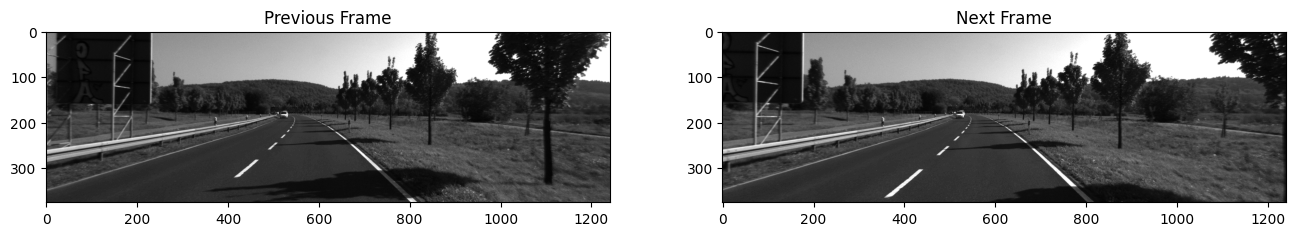

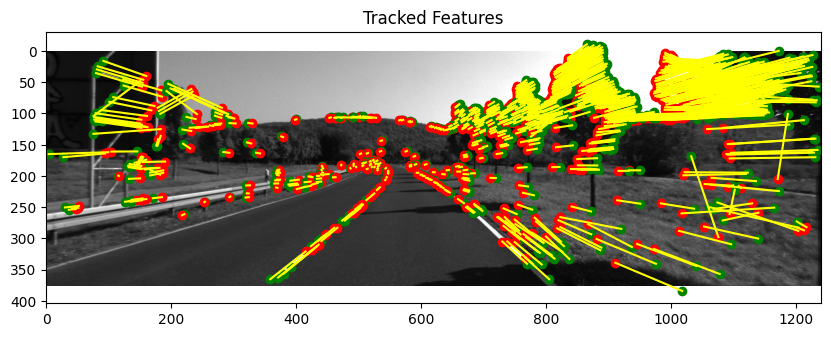

In [29]:
fast = cv2.FastFeatureDetector_create(threshold=32, nonmaxSuppression=True)

# --- First frame ---
prev_img = cv2.imread(image_files[0], cv2.IMREAD_GRAYSCALE)
keypoints = fast.detect(prev_img, None)
prev_pts = np.array([kp.pt for kp in keypoints], dtype=np.float32)

# Track previous points with optical flow
next_img = cv2.imread(image_files[1], cv2.IMREAD_GRAYSCALE)
next_pts, status, _ = cv2.calcOpticalFlowPyrLK(prev_img, next_img, prev_pts, None)
status = status.flatten()

# Keep only successfully tracked points
good_new = next_pts[status == 1]
good_old = prev_pts[status == 1]

print(f"Detected keypoints: {len(prev_pts)}")
print(f"Tracked keypoints: {len(good_new)}")

# Show the two images side by side
plt.figure(figsize=(16, 10))
plt.subplot(1, 2, 1)
plt.imshow(prev_img, cmap='gray')
plt.title("Previous Frame")
plt.subplot(1, 2, 2)
plt.imshow(next_img, cmap='gray')
plt.title("Next Frame")
plt.show()

# Plot tracked points
plt.figure(figsize=(10, 6))
plt.imshow(next_img, cmap='gray')
for i, (new, old) in enumerate(zip(good_new, good_old)):
    a, b = new.ravel()
    c, d = old.ravel()
    plt.plot([c, a], [d, b], color='yellow')
    plt.scatter(a, b, color='green')
    plt.scatter(c, d, color='red')
plt.title("Tracked Features")
plt.show()




E:
[[ 2.64622658e-04 -7.07035475e-01 -9.76319949e-03]
 [ 7.07010596e-01  2.32949266e-04  4.83007631e-03]
 [ 1.06135711e-02 -2.33043890e-03  4.02741654e-05]]

c2_R_c1:
[[ 9.99993715e-01  3.25515927e-04  3.53057280e-03]
 [-3.21275081e-04  9.99999226e-01 -1.20167847e-03]
 [-3.53096124e-03  1.20053663e-03  9.99993045e-01]]

c2_t_c1:
[[ 0.00330063]
 [ 0.01500889]
 [-0.99988191]]
norm of c2_t_c1: 0.9999999999999999

c1_T_c2:
 [[ 9.99993715e-01 -3.21275081e-04 -3.53096124e-03 -6.82632804e-03]
 [ 3.25515927e-04  9.99999226e-01  1.20053663e-03 -1.38095580e-02]
 [ 3.53057280e-03 -1.20167847e-03  9.99993045e-01  9.99881342e-01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]

Inliers: 840 / 896


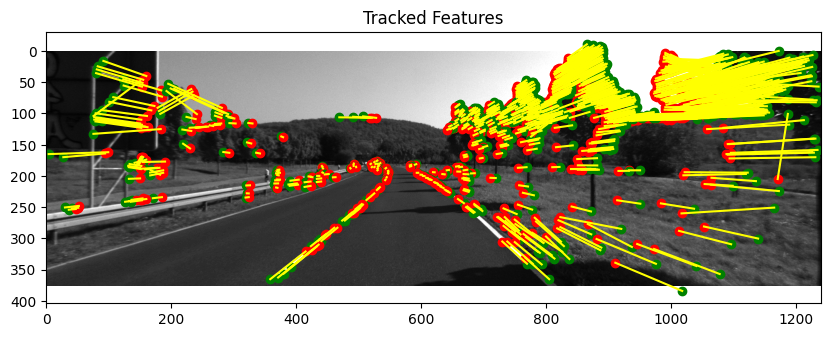

In [30]:
# Estimate Essential matrix
E, inliers = cv2.findEssentialMat(good_old, good_new, K, method=cv2.RANSAC, prob=0.95, threshold=0.1)

# Recover pose from Essential matrix
num_inliers, c2_R_c1, c2_t_c1, mask = cv2.recoverPose(E, good_old, good_new, K)

# Select only inlier correspondences
inlier_mask = mask.ravel().astype(bool)
pts1_inl = good_old[inlier_mask]
pts2_inl = good_new[inlier_mask]

print(f"E:\n{E}")
print()
print(f"c2_R_c1:\n{c2_R_c1}")
print()
print(f"c2_t_c1:\n{c2_t_c1}")
print("norm of c2_t_c1:", np.linalg.norm(c2_t_c1))
print()
print("c1_T_c2:\n", c1_T_c2)
print()
print(f"Inliers: {num_inliers} / {len(good_old)}")

# Plot inliers points
plt.figure(figsize=(10, 6))
plt.imshow(next_img, cmap='gray')
for i, (new, old) in enumerate(zip(pts2_inl, pts1_inl)):
    a, b = new.ravel()
    c, d = old.ravel()
    plt.plot([c, a], [d, b], color='yellow')
    plt.scatter(a, b, color='green')
    plt.scatter(c, d, color='red')
plt.title("Tracked Features")
plt.show()



P1:
 [[718.856    0.     607.1928   0.    ]
 [  0.     718.856  185.2157   0.    ]
 [  0.       0.       1.       0.    ]]

P2:
 [[ 7.16707507e+02  9.62956275e-01  6.09726551e+02 -6.04748423e+02]
 [-8.84939977e-01  7.19077802e+02  1.84350578e+02 -1.74404598e+02]
 [-3.53096124e-03  1.20053663e-03  9.99993045e-01 -9.99881913e-01]]


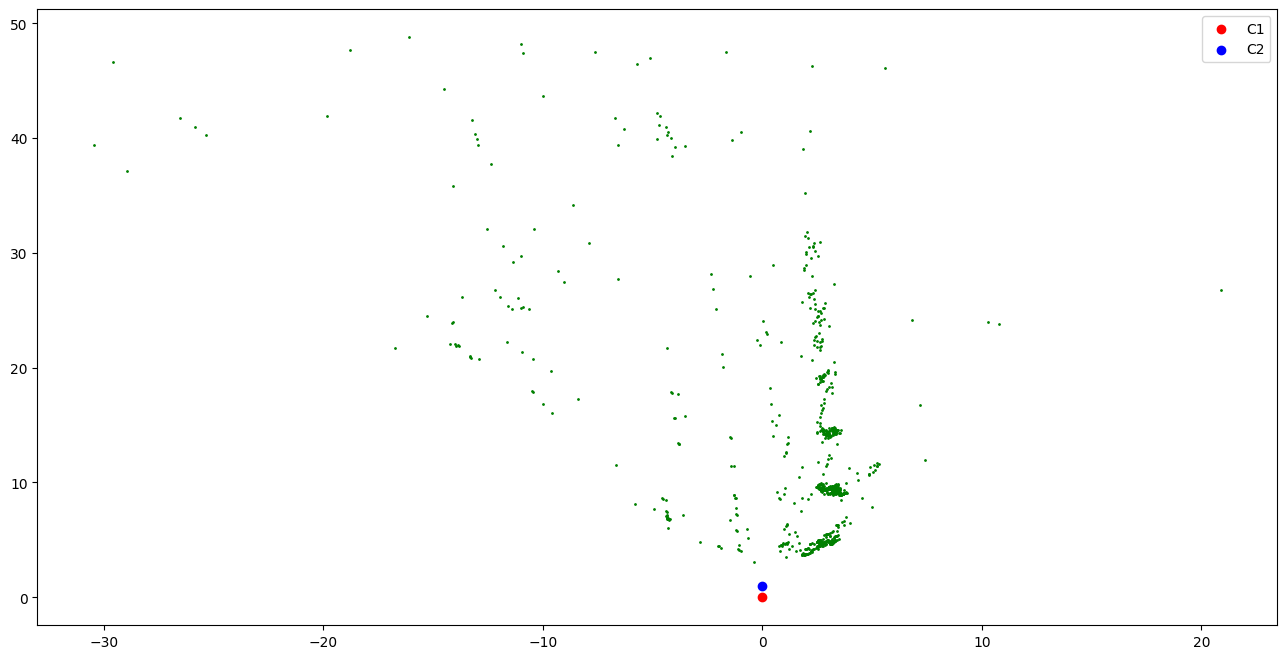

In [35]:
# Projection matrices
P1 = K @ np.hstack([np.eye(3), np.zeros((3, 1))])
P2 = K @ np.hstack([c2_R_c1, c2_t_c1])

print("P1:\n", P1)
print()
print("P2:\n", P2)

# Triangulate
points_h = cv2.triangulatePoints(P1, P2, pts1_inl.T, pts2_inl.T)

# Convert from homogeneous to 3D
points_3d = (points_h[:3] / points_h[3]).T

# Invert pose to get camera 2 in world coordinates
c1_T_c2 = np.linalg.inv(np.vstack([np.hstack([c2_R_c1, c2_t_c1]), [0, 0, 0, 1]]))

plt.figure(figsize=(16, 8))
plt.scatter(points_3d[:, 0], points_3d[:, 2], c="green", s=1)
plt.scatter(0, 0, c="red", label="C1")
plt.scatter(c1_T_c2[0, 3], c1_T_c2[2, 3], c="blue", label="C2")
plt.legend()

(840, 1, 2)
Detected keypoints: 840
Tracked keypoints: 529


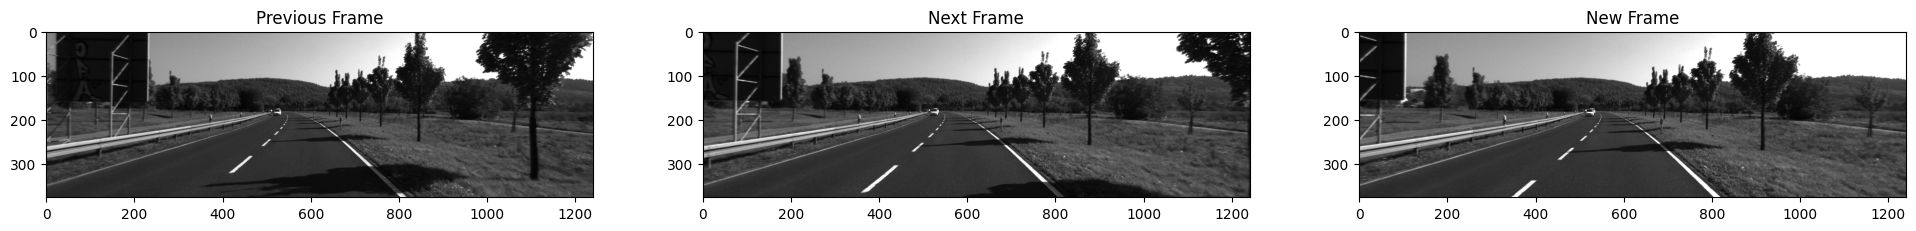

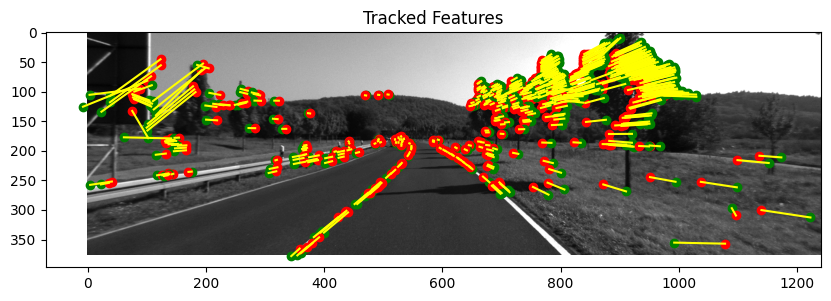

In [32]:
tracked_pts = pts2_inl.reshape(-1, 1, 2)
print(tracked_pts.shape)

new_img = cv2.imread(image_files[2], cv2.IMREAD_GRAYSCALE)
new_pts, status, _ = cv2.calcOpticalFlowPyrLK(next_img, new_img, tracked_pts, None)
status = status.flatten()

# Keep only successfully tracked points
good_old = pts2_inl[status == 1]
good_curr = new_pts[status == 1]
good_pts_3d = points_3d[status == 1]

print(f"Detected keypoints: {len(pts2_inl)}")
print(f"Tracked keypoints: {len(good_old)}")

# Plot the three images side by side with tracked points
plt.figure(figsize=(24, 8))
plt.subplot(1, 3, 1)
plt.imshow(prev_img, cmap="gray")
plt.title("Previous Frame")
plt.subplot(1, 3, 2)
plt.imshow(next_img, cmap="gray")
plt.title("Next Frame")
plt.subplot(1, 3, 3)
plt.imshow(new_img, cmap="gray")
plt.title("New Frame")
plt.show()
# Plot tracked points
plt.figure(figsize=(10, 6))
plt.imshow(new_img, cmap="gray")
for i, (new, old) in enumerate(zip(good_curr, good_old)):
    a, b = new.ravel()
    c, d = old.ravel()
    plt.plot([c, a], [d, b], color="yellow")
    plt.scatter(a, b, color="green")
    plt.scatter(c, d, color="red")
plt.title("Tracked Features")
plt.show()

In [36]:
# Solve PnP with RANSAC
success, rvec, tvec, inliers = cv2.solvePnPRansac(
    good_pts_3d, good_curr, K, distCoeffs=None, flags=cv2.SOLVEPNP_ITERATIVE)
if not success:
    raise RuntimeError(f"PnP failed")

# Convert to rotation matrix
c3_R_c1, _ = cv2.Rodrigues(rvec)
c3_t_c1 = tvec.ravel().reshape(3, 1)

print(f"c3_R_c1:\n{c3_R_c1}")
print()
print(f"c3_t_c1:\n{c3_t_c1}")

# Invert pose to get camera 3 in world coordinates
c1_T_c3 = np.linalg.inv(np.vstack([np.hstack([c3_R_c1, c3_t_c1]), [0, 0, 0, 1]]))
print()
print("c1_T_c3:\n", c1_T_c3)

c3_R_c1:
[[ 9.99978613e-01  1.63130781e-03  6.33337361e-03]
 [-1.62874093e-03  9.99998589e-01 -4.10431293e-04]
 [-6.33403422e-03  4.00107090e-04  9.99979860e-01]]

c3_t_c1:
[[ 0.00734419]
 [ 0.02697648]
 [-1.99608967]]

c1_T_c3:
 [[ 9.99978613e-01 -1.62874093e-03 -6.33403422e-03 -1.99434003e-02]
 [ 1.63130781e-03  9.99998589e-01  4.00107090e-04 -2.61897693e-02]
 [ 6.33337361e-03 -4.10431293e-04  9.99979860e-01  1.99601403e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


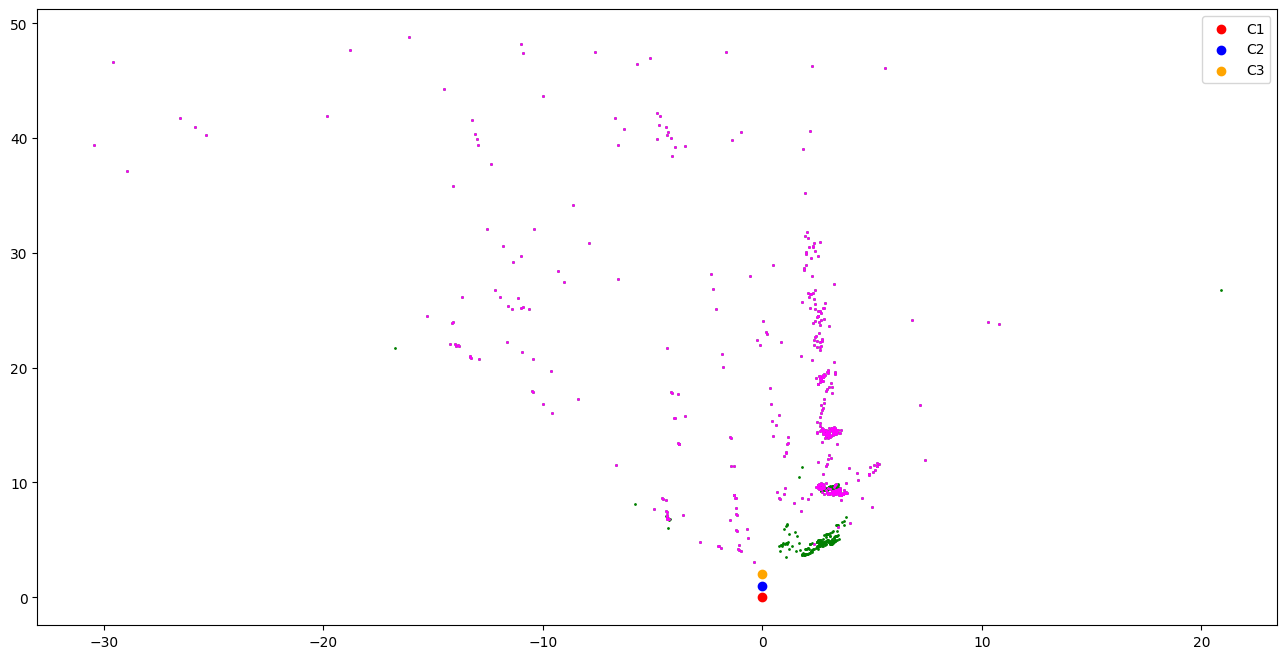

In [34]:
plt.figure(figsize=(16, 8))
plt.scatter(points_3d[:, 0], points_3d[:, 2], c="green", s=1)
plt.scatter(good_pts_3d[:, 0], good_pts_3d[:, 2], c="magenta", s=1)
plt.scatter(0, 0, c="red", label="C1")
plt.scatter(c1_T_c2[0, 3], c1_T_c2[2, 3], c="blue", label="C2")
plt.scatter(c1_T_c3[0, 3], c1_T_c3[2, 3], c="orange", label="C3")
plt.legend()